# MEDIDAS DE POSIÇÃo
Elementos que caracterizam uma determinada amostra ou distribuição

In [1]:
# IMPORTS
import numpy as np
import pandas as pd
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
#MÉDIA - soma de todos os valores dividos pela quantitade
#Sensível a outliers (um valor extremo puxa a média)

lista_desc = [1, 2, 3, 4, 5, 6, 6]
print(np.mean(lista_desc))  # resultado: 3.857

3.857142857142857


In [ ]:
#MEDIANA - valor que divide a amostra ao meio:
#50% dos valores estão abaixo, 50% acima
#Robusta a outliers (o CEO rico não distorce)

print(np.median(lista_desc))  # resultado: 4.00)

4.0


In [ ]:
#MODA - valor que aparece com mais frequência
#Única medida que funciona para dados qualitativos
#Uma distribuição pode ter mais de uma moda (bimodal)
#Python não tem função nativa para moda, tem que importar scipy

print(stats.mode(lista_desc))  # resultado: 6 (aparece 2x)

ModeResult(mode=np.int64(6), count=np.int64(2))


In [ ]:
# MÉDIA APARADA (TRIMMED MEAN)
# Descarta uma % dos valores extremos de cada lado
# Meio-termo entre a média (sensível a outliers) e a mediana (ignora magnitude)

salarios = [3000, 3000, 3000, 3000, 3000, 3000, 3000, 3000, 3000, 47000]

media = np.mean(salarios)
mediana = np.median(salarios)
media_aparada = stats.trim_mean(salarios, 0.1)  # descarta 10% de cada lado

print(f"Média comum:   R$ {media:,.0f}")      # puxada pelo CEO
print(f"Mediana:       R$ {mediana:,.0f}")    # ignora o CEO
print(f"Média aparada: R$ {media_aparada:,.0f}")  # CEO removido do cálculo

Média comum:   R$ 7,400
Mediana:       R$ 3,000
Média aparada: R$ 3,000


In [ ]:
## Percentis, Quartis e Decis
# Medem a posição relativa de um valor dentro da distribuição.
# - Percentil 75 = 75% dos dados ficam abaixo desse valor
# - Quartis dividem em 4 partes iguais (Q1=P25, Q2=P50, Q3=P75)
# - IQR (Intervalo Entre Quartis) = Q3 - Q1 → faixa dos 50% centrais, livre dos extremos
# - Decis dividem em 10 partes iguais

df["column"].quantile(0.25)
#quantile() é universal, é necessário informar o valor que se quer cortar


# MEDIDAS DE DISPERSÃO
# Medidas que mostram como os dados se afastam do centro
# É uma medida rápida, só para ter uma noção do range; basta um outlier para descaracterizar a amostra

In [ ]:
# banco de dados de exemplo
salarios = pd.read_csv("G:/Meu Drive/MBA USP Esalq - Data Science, AI, Analytics/02 - Programação em Python/Introdução Programação Python/jobs_in_data_2024.csv",sep=",")

In [ ]:
# AMPLITUDE
# Distância entre o máximo e o mínimo valor
amplitude = salarios["salary"].max() - salarios["salary"].min()
print (amplitude)

436000


In [ ]:
# VARIÂNCIA
# Média dos quadrados das diferenças em relação à média
# Elevou-se ao quadrado para evitar que valores positivos e negativos se anulem
# Lembre-se: estamos estudando o quando os valores se afastam da média
# Sozinha é difícil de interpretar, porém é um cálculo usando em ANOVA, regressão e testes de hipóteses - um mal necessário
# Ela permite o próximo conceito - desvio padrão

salarios["salary"].var()

np.float64(4216170356.6508565)

In [ ]:
# DESVIO PADRÃO
# Quadrado da variância. O objetivo é voltar à unidade original - lembre-se: nós elevamos ao quadrado para que positivo e negativos não se anulassem
# É como a "margem de erro típica" dos dados. A maior parte dos valores deve estar nessa faixa a partir da média, para cima e para baixo.
# Quem estiver toda disso começa a chamar a atenção

salarios["salary"].std()

np.float64(64932.04414348016)

In [ ]:
# COEFICIENTE DE VARIAÇÃO - cv
# Medida de dispersão relativa, por relaciona o desvio padrão e a média
# Permite realizar comparações entre amostras
# Quanto menor o CV, mais homgêneos os valores da variável e mais concentrados estão os valores em torno da amostra
# Abaixo de 15%: Distribuição homogênea — dados colados na média
# 15% a 30%: Dispersão moderada
# Acima de 30%: Distribuição heterogênea — dados espalhados
# Nota adicional: mercados com CV abaixo de 15% são considerados homogêneos, e acima de 30% são considerados heterogêneos

CV = salarios["salary"].std() / salarios["salary"].mean()*100

In [ ]:
# ERRO PADRÃO
# É o desvio padrão da média da variável
# Mede como diferentes amostras variam entre si
# Quando maior o tamanho da amostra, menor o erro padrão na estimativa da média da variável - mais precisa e confiável é a média estimada
# Calcular a média e desvio padrão de uma amostra de 10 pessoas é diferente de calcular a média e desvio padrão de uma amostra de 10.000 pessoas;
# quanto maior a amostra, mais precisas a média e o desvio padrão
# Erro Padrão = Desvio Padrão / √n

n = len(salarios["salary"])
desvio = salarios["salary"].std()
erro_padrao = desvio/np.sqrt(n)

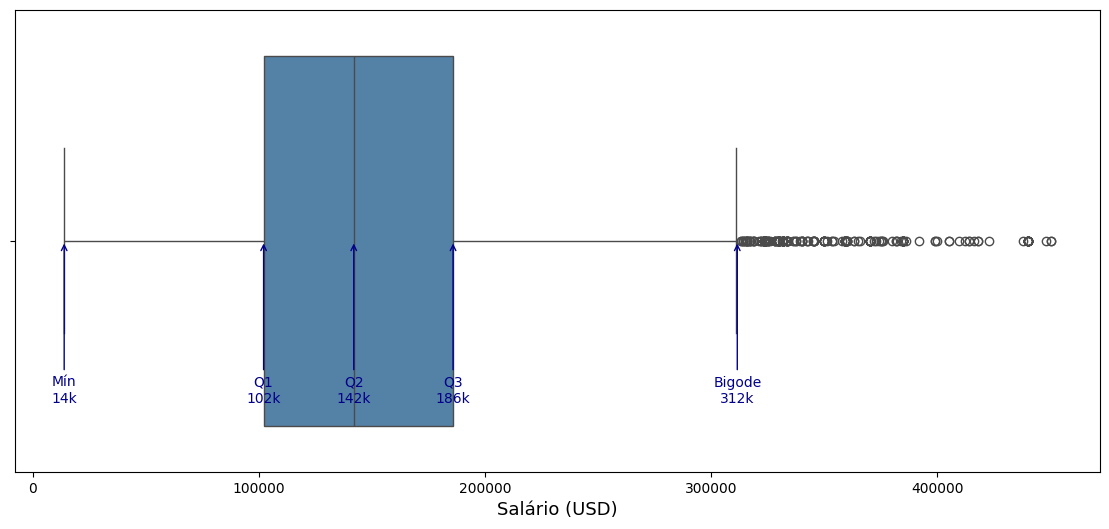

In [ ]:
# BOXPLOT PARA ILUSTRAR AS MEDIDAS DE POSIÇÃO E DISPERSÃO

fig, ax = plt.subplots(figsize=(14, 6))
sns.boxplot(data=salarios, x='salary', color='steelblue', ax=ax)

# Valores calculados
q1  = salarios['salary'].quantile(0.25)
q2  = salarios['salary'].quantile(0.50)
q3  = salarios['salary'].quantile(0.75)
iqr = q3 - q1
bigode_min = salarios['salary'].min()
bigode_max = q3 + 1.5 * iqr

# Anotações
for valor, label in [
    (bigode_min, f'Mín\n{bigode_min/1000:.0f}k'),
    (q1,         f'Q1\n{q1/1000:.0f}k'),
    (q2,         f'Q2\n{q2/1000:.0f}k'),
    (q3,         f'Q3\n{q3/1000:.0f}k'),
    (bigode_max, f'Bigode\n{bigode_max/1000:.0f}k'),
]:
    ax.annotate(label, xy=(valor, 0), xytext=(valor, 0.35),
                ha='center', fontsize=10, color='darkblue',
                arrowprops=dict(arrowstyle='->', color='darkblue', lw=1))

plt.xlabel('Salário (USD)', fontsize=13)

plt.show()

In [ ]:
# BIGODE INFERIOR E SUPERIOR DO BOXPLOT
# BI = Q1 - 1,5 x IQR
# BS = Q3 + 1,5 x IQR

# Valores acima ou abaixo disso são considerados outliers

limite_superior = salarios["salary"].quantile(0.75)+1.5*(salarios["salary"].quantile(0.75)-salarios["salary"].quantile(0.25))
outliers = salarios[salarios["salary"] > limite_superior]
print(len(outliers))

224


## MEDIDAS DE FORMA
# Medidas que respondem à pergunta: qual o formato da distribuição?

In [ ]:
# ASSIMETRIA (SKEWNESS)
# Local de concentração da distribuição
# A assimetria quantifica o quando a distribuição está inclinada para um lado

# Valores
# Assimetria = 0   simérica
# Assimetria > 0   cauda à direita (positiva)
# Assimetria < 0   cauda à esquerda

#Interpretação
# Entre -0,5 e +0,5 : Aproximadamente simétrica
# Entre 0,5 e 1,0 : Assimetria moderada
# Acima de 1,0 : Assimetria forte

salarios["salary"].skew()


In [ ]:
salarios["salary"].skew()

np.float64(0.6930466672955429)

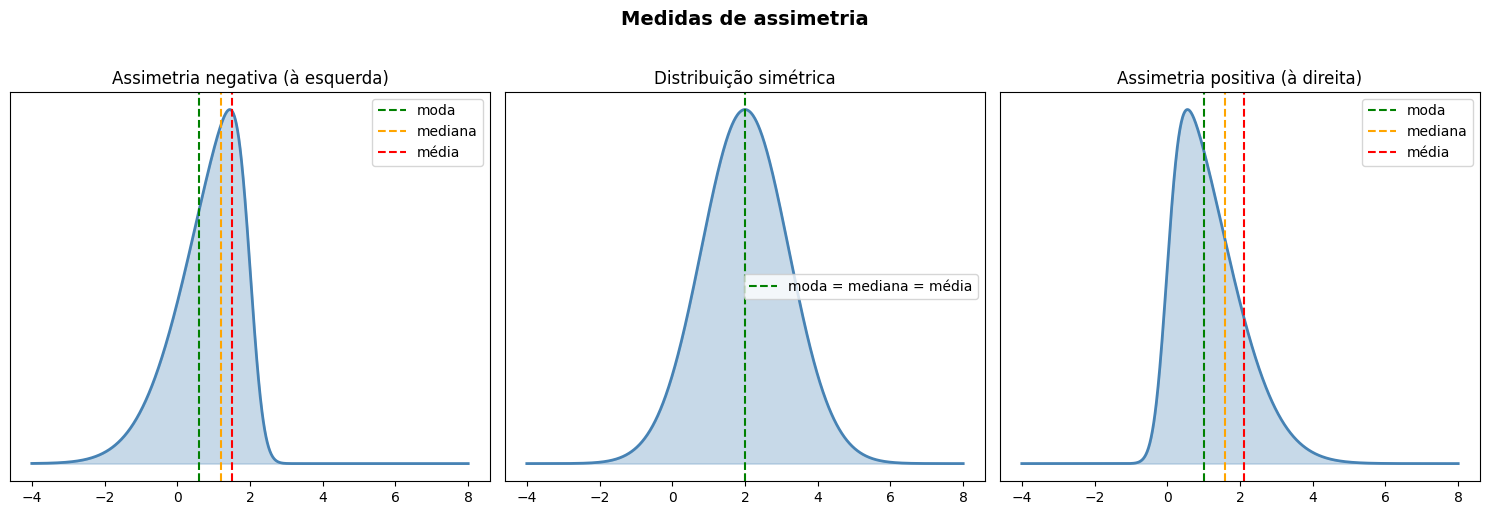

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

x = np.linspace(-4, 8, 1000)

# Assimetria negativa (à esquerda)
dados_neg = stats.skewnorm.pdf(x, a=-5, loc=2, scale=1.5)
axes[0].plot(x, dados_neg, color='steelblue', linewidth=2)
axes[0].fill_between(x, dados_neg, alpha=0.3, color='steelblue')
axes[0].axvline(x=0.6, color='green',  linestyle='--', label='moda')
axes[0].axvline(x=1.2, color='orange', linestyle='--', label='mediana')
axes[0].axvline(x=1.5, color='red',    linestyle='--', label='média')
axes[0].set_title('Assimetria negativa (à esquerda)', fontsize=12)
axes[0].legend(fontsize=10)
axes[0].set_yticks([])

# Simétrica
dados_sim = stats.norm.pdf(x, loc=2, scale=1.2)
axes[1].plot(x, dados_sim, color='steelblue', linewidth=2)
axes[1].fill_between(x, dados_sim, alpha=0.3, color='steelblue')
axes[1].axvline(x=2, color='green',  linestyle='--', label='moda = mediana = média')
axes[1].set_title('Distribuição simétrica', fontsize=12)
axes[1].legend(fontsize=10)
axes[1].set_yticks([])

# Assimetria positiva (à direita)
dados_pos = stats.skewnorm.pdf(x, a=5, loc=0, scale=1.5)
axes[2].plot(x, dados_pos, color='steelblue', linewidth=2)
axes[2].fill_between(x, dados_pos, alpha=0.3, color='steelblue')
axes[2].axvline(x=1.0, color='green',  linestyle='--', label='moda')
axes[2].axvline(x=1.6, color='orange', linestyle='--', label='mediana')
axes[2].axvline(x=2.1, color='red',    linestyle='--', label='média')
axes[2].set_title('Assimetria positiva (à direita)', fontsize=12)
axes[2].legend(fontsize=10)
axes[2].set_yticks([])

plt.suptitle('Medidas de assimetria', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
# CURTOSE (KURTOSIS)
# Medida de achatamento da curva de distribuição
# Mede o peso das caudas e o quanto elas puxam a ponta da curva - o quando as curvas possuem muitos ou poucos valores extremos
# Com a curva normal como referência, é possível observar se as curvas têm maior ou menor dispersão em torno da média
# Uma distribuição com curtose alta tem mais outliers do que a normal esperaria

# Valores
# Curtose = 0   → normal (mesocúrtica) - Normal padrão
# Curtose > 0   → mais pontuda, caudas pesadas (leptocúrtica), mais outliers
# Curtose < 0   → mais achatada, caudas leves (platicúrtica), poucos outliers

salarios["salary"].kurt()

np.float64(0.7913866124530333)

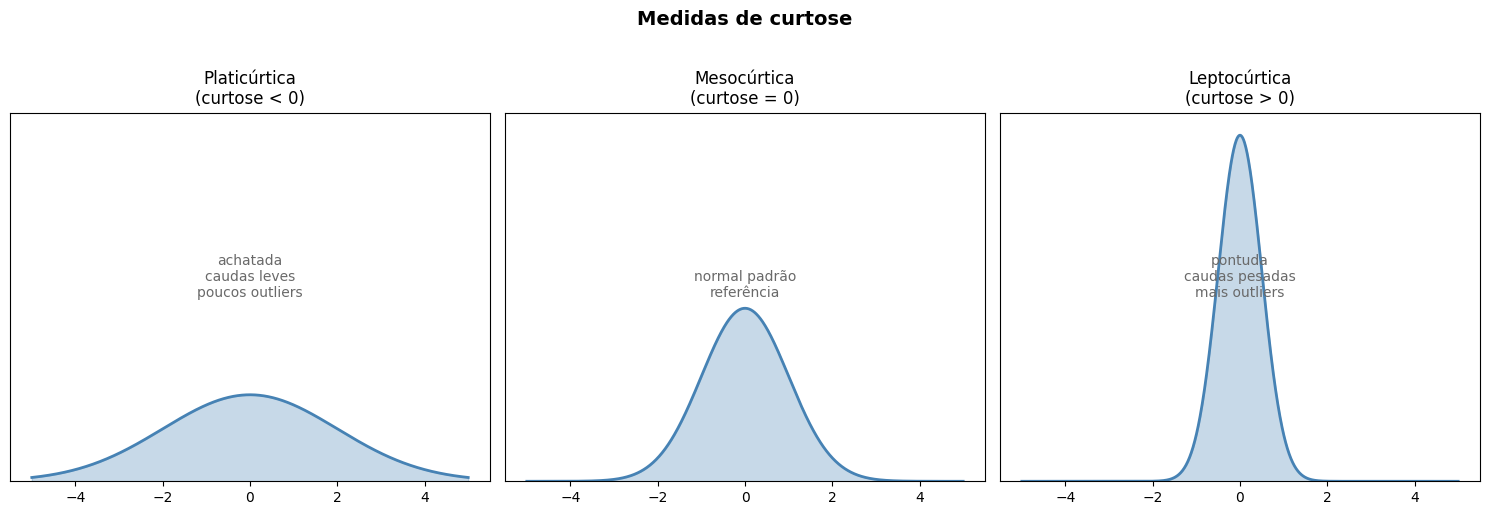

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

x = np.linspace(-5, 5, 1000)

# Mesocúrtica — normal padrão (referência)
y_meso = stats.norm.pdf(x, scale=1.0)

# Platicúrtica — achatada (desvio maior = mais espalhada)
y_plati = stats.norm.pdf(x, scale=2.0)

# Leptocúrtica — pontuda (desvio menor = mais concentrada)
y_lepto = stats.norm.pdf(x, scale=0.5)

ymax = 0.85  # escala igual nos três

for ax, y, titulo, subtitulo, descricao in [
    (axes[0], y_plati, 'Platicúrtica', '(curtose < 0)', 'achatada\ncaudas leves\npoucos outliers'),
    (axes[1], y_meso,  'Mesocúrtica',  '(curtose = 0)', 'normal padrão\nreferência'),
    (axes[2], y_lepto, 'Leptocúrtica', '(curtose > 0)', 'pontuda\ncaudas pesadas\nmais outliers'),
]:
    ax.plot(x, y, color='steelblue', linewidth=2)
    ax.fill_between(x, y, alpha=0.3, color='steelblue')
    ax.set_title(f'{titulo}\n{subtitulo}', fontsize=12)
    ax.set_ylim(0, ymax)
    ax.set_yticks([])
    ax.annotate(descricao, xy=(0, ymax*0.5), ha='center', fontsize=10, color='dimgray')

plt.suptitle('Medidas de curtose', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()